# Compte rendu de TP : Détection de contours
## Méthodes classiques, HED et fusion hybride
**Module :** Vision par ordinateur  
**Nom(s) et prénom(s) :** Amine BOURAMTANE  

### Objectif et problématique
Ce travail met en œuvre Sobel, Canny et le réseau pré-entraîné HED, puis étudie une fusion pondérée des cartes Canny et HED. L'objectif est de déterminer si la combinaison conserve les détails utiles tout en renforçant les contours structurants.

**Plan :** préparation ; partie A (prétraitement et méthodes classiques) ; partie B (HED) ; partie C (fusion) ; partie D (comparaison et mesures) ; réponses aux huit questions ; extension et conclusion.

**Conditions de l'étude.** Aucune image personnelle n'accompagnait l'énoncé. L'expérience utilise donc la photographie publique *Astronaut* (Eileen Collins, NASA), distribuée avec scikit-image, enregistrée dans `image.jpg`. Les observations concernent cette image. Les cellules et leurs sorties sont conservées dans ce notebook ; les temps sont mesurés sur la machine d'exécution et ne constituent pas des performances universelles. Aucune vérité terrain n'est fournie : aucune précision de détection n'est inventée.

## 0. Préparation et reproductibilité
Le dossier doit contenir ce notebook, `image.jpg`, `deploy.prototxt` et `hed_pretrained_bsds.caffemodel`. Les fichiers sont fournis avec ce compte rendu. Exécuter les cellules dans l'ordre, depuis ce dossier.

Si nécessaire, décommenter la ligne d'installation ci-dessous. `opencv-python-headless` convient au notebook, car les images sont affichées avec Matplotlib. Le TP utilise OpenCV 4.12, qui fournit le chargeur Caffe requis. Ne pas installer simultanément plusieurs distributions OpenCV dans le même environnement.

In [1]:
# %pip install "opencv-python-headless==4.12.0.88" numpy matplotlib ipython scikit-image

In [1]:
from pathlib import Path
from time import perf_counter
import sys, platform, hashlib, csv
import cv2
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = Path.cwd()
IMAGE_PATH = ROOT / "image.jpg"
PROTO_PATH = ROOT / "deploy.prototxt"
MODEL_PATH = ROOT / "hed_pretrained_bsds.caffemodel"
OUT = ROOT / "resultats"
OUT.mkdir(exist_ok=True)
cv2.setNumThreads(2)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})

for path in (IMAGE_PATH, PROTO_PATH, MODEL_PATH):
    if not path.is_file():
        raise FileNotFoundError(f"Fichier requis absent : {path}. Voir les sources en fin de notebook.")
print(f"Python {sys.version.split()[0]} | OpenCV {cv2.__version__} | NumPy {np.__version__}")
print(f"Matplotlib {matplotlib.__version__} | {platform.system()} {platform.machine()}")
print(f"CPU : OpenCV limité à {cv2.getNumThreads()} threads")
print("SHA-256 du modèle :", hashlib.sha256(MODEL_PATH.read_bytes()).hexdigest())

def normalize01(a):
    a = np.asarray(a, dtype=np.float32)
    lo, hi = float(a.min()), float(a.max())
    return (a - lo) / (hi - lo) if hi > lo else np.zeros_like(a)

def show_grid(images, titles, filename, cols=3):
    rows = (len(images) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(5 * cols, 4.6 * rows), squeeze=False)
    for ax, im, title in zip(axes.flat, images, titles):
        if im.ndim == 2:
            ax.imshow(im, cmap="gray", vmin=0, vmax=1)
        else:
            ax.imshow(im)
        ax.set_title(title)
        ax.axis("off")
    for ax in axes.flat[len(images):]:
        ax.axis("off")
    fig.tight_layout()
    fig.savefig(OUT / filename, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)

def save_map(name, a):
    ok = cv2.imwrite(str(OUT / name), np.rint(np.clip(a, 0, 1) * 255).astype(np.uint8))
    if not ok:
        raise OSError(f"Échec d'enregistrement : {name}")

Python 3.10.20 | OpenCV 4.13.0 | NumPy 2.2.6
Matplotlib 3.10.8 | Linux x86_64
CPU : OpenCV limité à 2 threads
SHA-256 du modèle : 4b6937684bce9be1ef5163c78ec812dff9a23653bfbb451925210a64ecfaaac7


## Partie A — Prétraitement et méthodes classiques
### A.1–A.2. Chargement et flou gaussien
L'image est chargée en couleur (BGR pour OpenCV), puis convertie en niveaux de gris. Pour limiter le coût CPU de HED, sa plus grande dimension est ramenée à **384 pixels**, en conservant les proportions. Toutes les méthodes utilisent cette même résolution. L'original fourni reste inchangé.

Le prétraitement classique utilise un noyau gaussien $5\times5$ et $\sigma=1{,}2$. Il atténue les petites variations avant la dérivation, tout en préservant les grandes limites. HED reçoit l'image couleur sans ce flou, conformément au prétraitement du modèle.

Original : 512 × 512 ; résolution de travail : 384 × 384


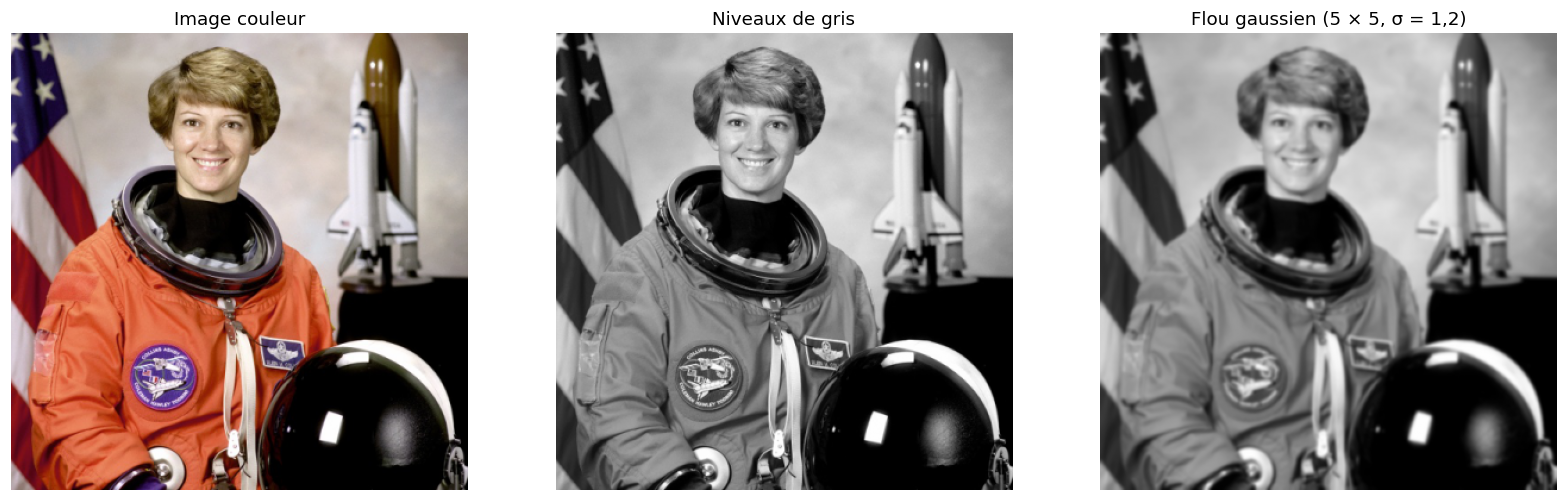

In [2]:
original_bgr = cv2.imread(str(IMAGE_PATH), cv2.IMREAD_COLOR)
if original_bgr is None:
    raise ValueError("L'image ne peut pas être décodée.")
h0, w0 = original_bgr.shape[:2]
scale = min(1.0, 384 / max(h0, w0))
img = cv2.resize(original_bgr, (round(w0 * scale), round(h0 * scale)), interpolation=cv2.INTER_AREA)
h, w = img.shape[:2]
rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
blur = cv2.GaussianBlur(gray, (5, 5), 1.2)
print(f"Original : {w0} × {h0} ; résolution de travail : {w} × {h}")
cv2.imwrite(str(OUT / "image_travail.png"), img)
show_grid([rgb, gray / 255., blur / 255.],
          ["Image couleur", "Niveaux de gris", "Flou gaussien (5 × 5, σ = 1,2)"], "A_pretraitement.png")

### A.3–A.5. Sobel et deux couples de seuils Canny
Sobel estime les dérivées horizontale et verticale : $G_x=I*K_x$ et $G_y=I*K_y$. La norme $G=\sqrt{G_x^2+G_y^2}$ représente l'intensité du gradient. Le calcul en flottants conserve les dérivées négatives ; la norme est ensuite normalisée pour l'affichage.

Canny combine dérivation, suppression des non-maxima et hystérésis : un contour fort dépasse le seuil haut ; un contour faible dépassant le seuil bas est conservé s'il est relié à un contour fort. Les couples étudiés sont **(50, 150)** et **(100, 200)**. Le flou est explicitement appliqué avant `cv2.Canny` ; la norme de gradient utilisée par défaut est L1 (`L2gradient=False`), comme dans le code de départ.

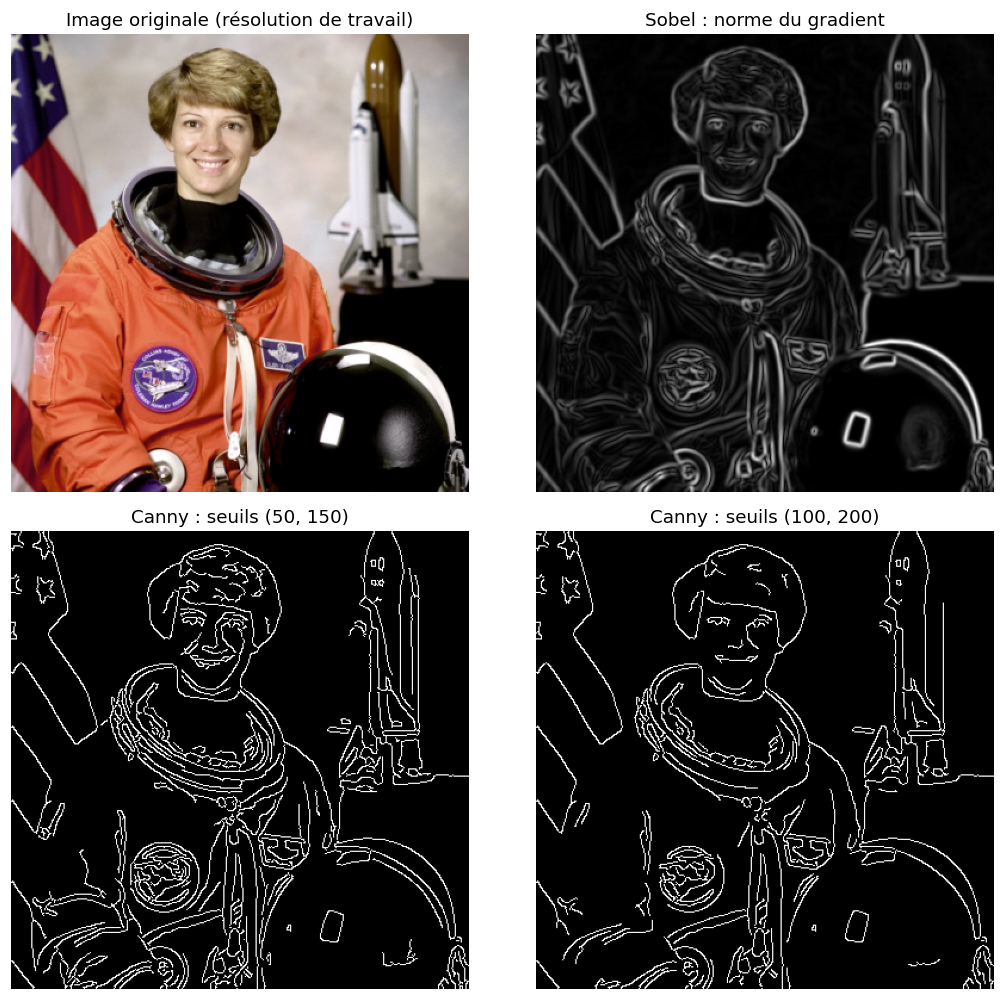

**Mesure :** 11,747 pixels de contour avec (50, 150), contre 8,999 avec (100, 200), soit une diminution de **23.4 %**. Cette quantité mesure la densité, pas la justesse des contours.

In [3]:
def sobel_map(b):
    gx = cv2.Sobel(b, cv2.CV_32F, 1, 0, ksize=3)
    gy = cv2.Sobel(b, cv2.CV_32F, 0, 1, ksize=3)
    return normalize01(cv2.magnitude(gx, gy))

sobel = sobel_map(blur)
canny_low = cv2.Canny(blur, 50, 150)
canny = cv2.Canny(blur, 100, 200)
canny_norm = canny.astype(np.float32) / 255.0
show_grid([rgb, sobel, canny_low / 255., canny_norm],
          ["Image originale (résolution de travail)", "Sobel : norme du gradient",
           "Canny : seuils (50, 150)", "Canny : seuils (100, 200)"], "A_contours.png", cols=2)
n_low, n_high = np.count_nonzero(canny_low), np.count_nonzero(canny)
display(Markdown(f"**Mesure :** {n_low:,} pixels de contour avec (50, 150), contre {n_high:,} avec (100, 200), soit une diminution de **{100*(n_low-n_high)/max(n_low,1):.1f} %**. Cette quantité mesure la densité, pas la justesse des contours."))
save_map("resultat_sobel.png", sobel)
save_map("resultat_canny_50_150.png", canny_low / 255.)
save_map("resultat_canny.png", canny_norm)

**Interprétation.** Sobel représente des bandes de gradient d'intensité variable, sans produire directement une sélection de contours fins. Canny fournit des lignes binaires plus fines. Le couple (100, 200) est retenu pour les fusions afin de limiter les réponses faibles. Ce choix conserve moins de détails et peut interrompre certaines limites peu contrastées ; il ne garantit pas à lui seul une meilleure détection.

## Partie B — Détection par deep learning
### B.1. Chargement de HED
HED (*Holistically-Nested Edge Detection*) exploite des caractéristiques convolutives à plusieurs échelles et combine des sorties intermédiaires. Les poids sont pré-entraînés : aucun entraînement n'est réalisé ici.

La couche `Crop` ci-dessous assure la compatibilité avec le réseau Caffe, suivant le principe de l'exemple officiel OpenCV. Le recadrage centre une carte de caractéristiques sur la taille cible. L'exécution utilise le backend OpenCV et le CPU.

In [5]:
class CropLayer:
    def __init__(self, params, blobs):
        self.top = self.left = self.bottom = self.right = 0

    def getMemoryShapes(self, inputs):
        source, target = inputs
        height, width = target[2:4]
        self.top = (source[2] - height) // 2
        self.left = (source[3] - width) // 2
        self.bottom, self.right = self.top + height, self.left + width
        return [[source[0], source[1], height, width]]

    def forward(self, inputs):
        return [inputs[0][:, :, self.top:self.bottom, self.left:self.right]]

# Autorise la réexécution de la cellule dans un même noyau.
try:
    cv2.dnn_unregisterLayer("Crop")
except cv2.error:
    pass
cv2.dnn_registerLayer("Crop", CropLayer)
t0 = perf_counter()
net = cv2.dnn.readNetFromCaffe(str(PROTO_PATH), str(MODEL_PATH))
net.setPreferableBackend(cv2.dnn.DNN_BACKEND_OPENCV)
net.setPreferableTarget(cv2.dnn.DNN_TARGET_CPU)
load_ms = (perf_counter() - t0) * 1000
print(f"Chargement du modèle : {load_ms:.1f} ms (séparé de l'inférence)")

Chargement du modèle : 117.6 ms (séparé de l'inférence)


### B.2–B.4. Prédiction, redimensionnement et normalisation
`blobFromImage` soustrait la moyenne BGR du modèle, sans permuter les canaux. La sortie est remise à la résolution de travail, puis normalisée par :

$$H=\frac{H_{\mathrm{brut}}-\min(H_{\mathrm{brut}})}{\max(H_{\mathrm{brut}})-\min(H_{\mathrm{brut}})}.$$

Une carte constante est ramenée à zéro pour éviter une division par zéro. La sortie du réseau est un score continu. Après cette normalisation min-max, son intensité doit être interprétée comme une **force relative de contour dans l'image**, et non comme une probabilité calibrée.

Sortie brute : [0.0000, 0.9949]
Après normalisation : [0.0000, 1.0000]


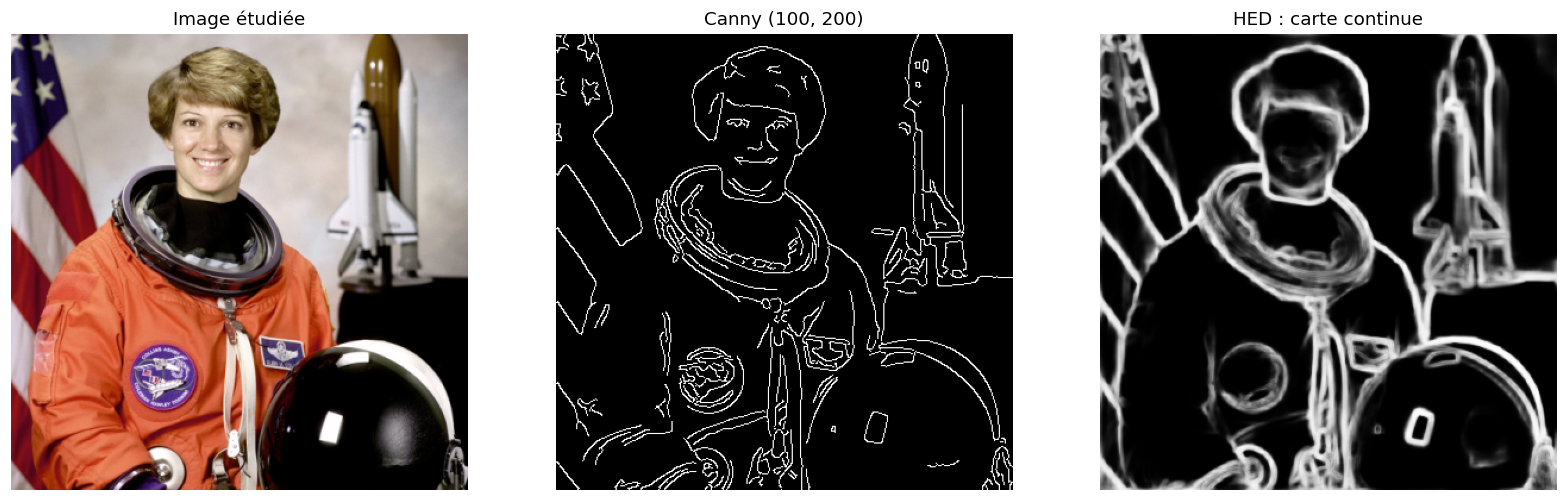

In [6]:
def predict_hed(bgr):
    height, width = bgr.shape[:2]
    blob = cv2.dnn.blobFromImage(
        bgr, scalefactor=1.0, size=(width, height),
        mean=(104.00698793, 116.66876762, 122.67891434),
        swapRB=False, crop=False)
    net.setInput(blob)
    raw = net.forward()[0, 0]
    raw = cv2.resize(raw, (width, height), interpolation=cv2.INTER_LINEAR)
    return raw, normalize01(raw)

hed_raw, hed = predict_hed(img)
print(f"Sortie brute : [{hed_raw.min():.4f}, {hed_raw.max():.4f}]")
print(f"Après normalisation : [{hed.min():.4f}, {hed.max():.4f}]")
show_grid([rgb, canny_norm, hed], ["Image étudiée", "Canny (100, 200)", "HED : carte continue"], "B_HED.png")
save_map("resultat_hed.png", hed)

### B.5. Deux différences visuelles
1. **Épaisseur et continuité.** HED dessine les grandes limites avec des bandes plus larges et une intensité progressive. Canny les localise par des lignes fines, mais certaines parties faibles peuvent disparaître après seuillage.
2. **Sélection des détails.** Dans le zoom du visage, Canny dessine nettement les yeux et la bouche, alors que HED atténue fortement ces détails et souligne surtout la limite cheveux/front et le bas du visage. Dans le zoom de la combinaison, HED conserve surtout le pourtour de l’écusson circulaire ; Canny en représente aussi les motifs internes. Cette sélection n’est donc pas identique entre les deux approches.

Les agrandissements de la partie suivante permettent d'examiner ces différences sur l'image effectivement traitée.

## Partie C — Fusion hybride
### C.1–C.3. Normalisation, calcul et affichage
La carte Canny binaire est divisée par 255. Les deux cartes sont donc dans $[0,1]$ et de même taille. On calcule :

$$F_\alpha=\alpha H+(1-\alpha)C,\qquad \alpha\in\{0{,}3;0{,}6;0{,}8\}.$$

Il s'agit d'une combinaison convexe : la fusion reste dans $[0,1]$. **On ne renormalise pas séparément chaque fusion**, afin de préserver l'effet des poids. Toutes les cartes sont affichées avec la même échelle de gris (0 à 1).

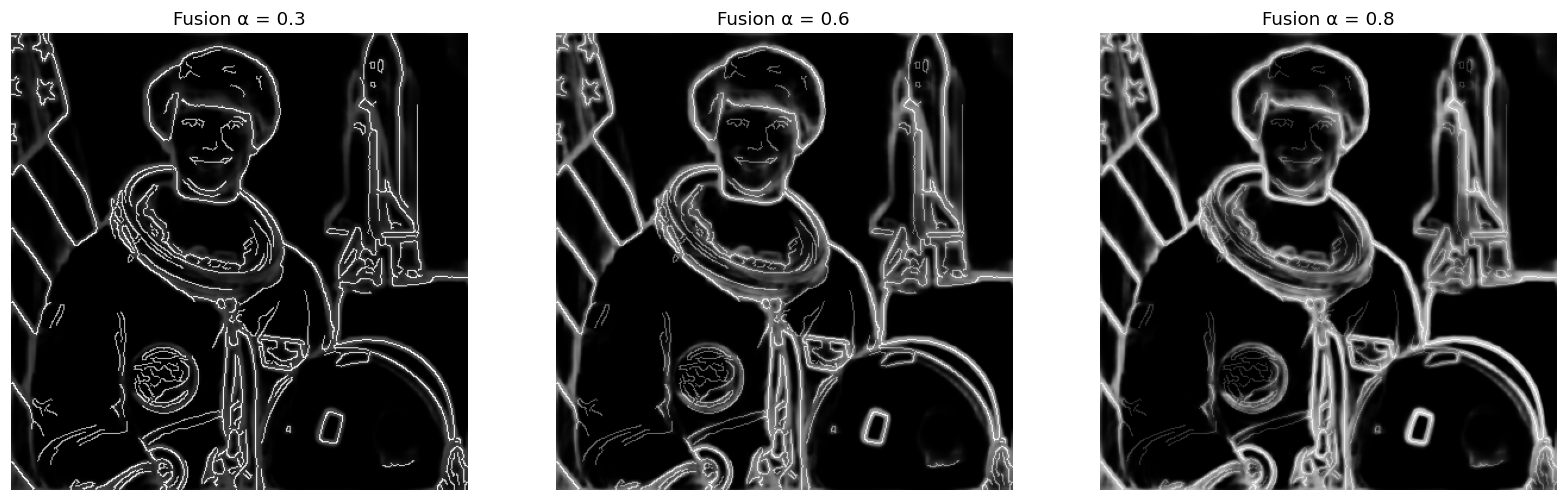

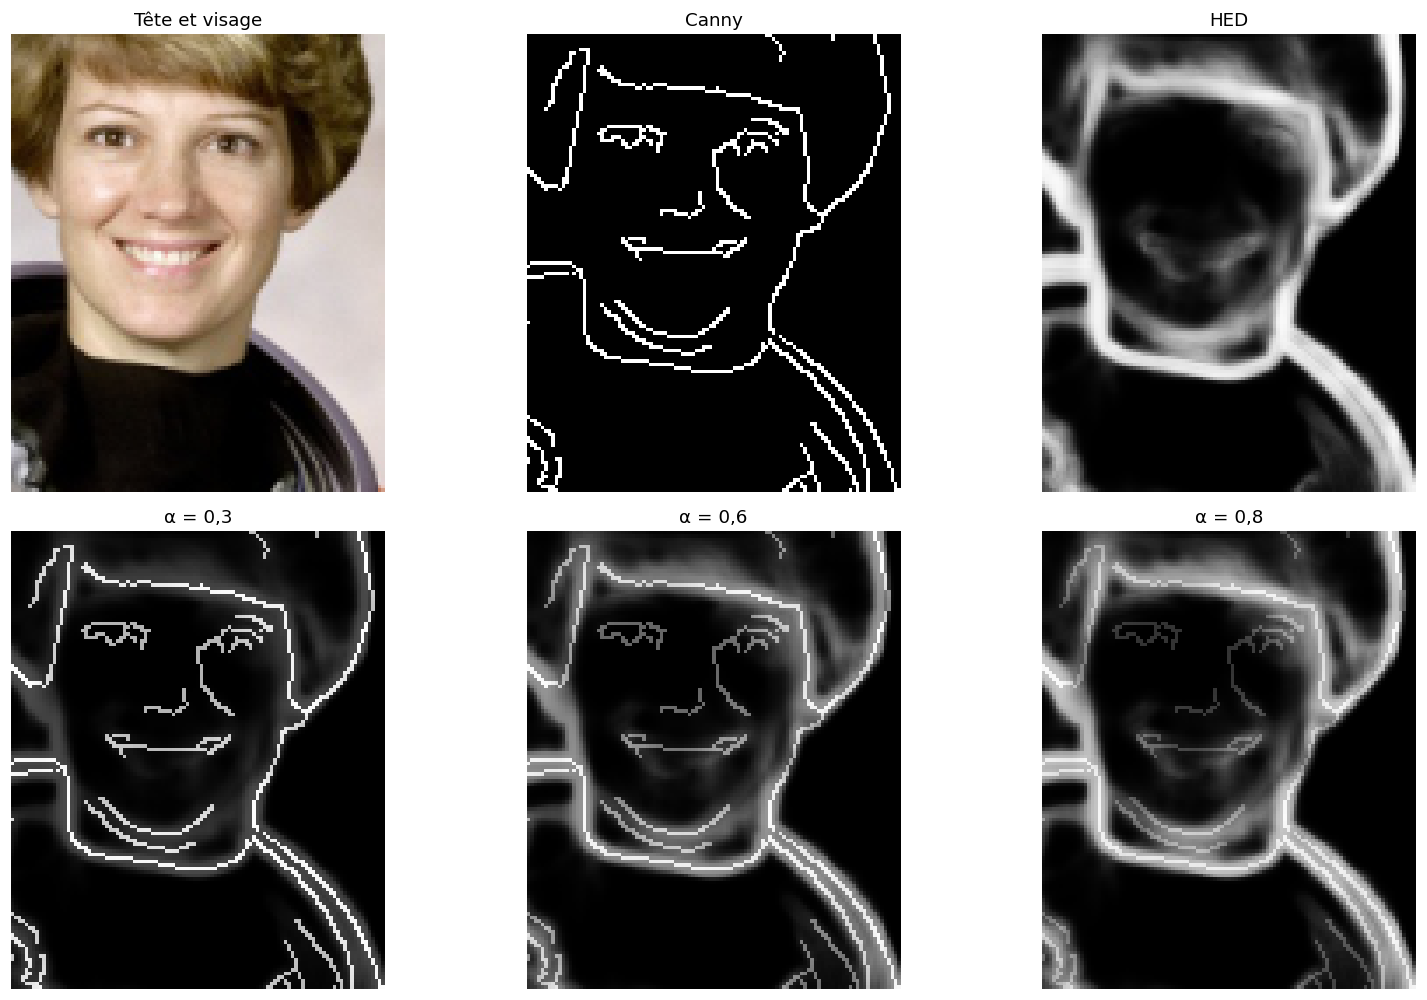

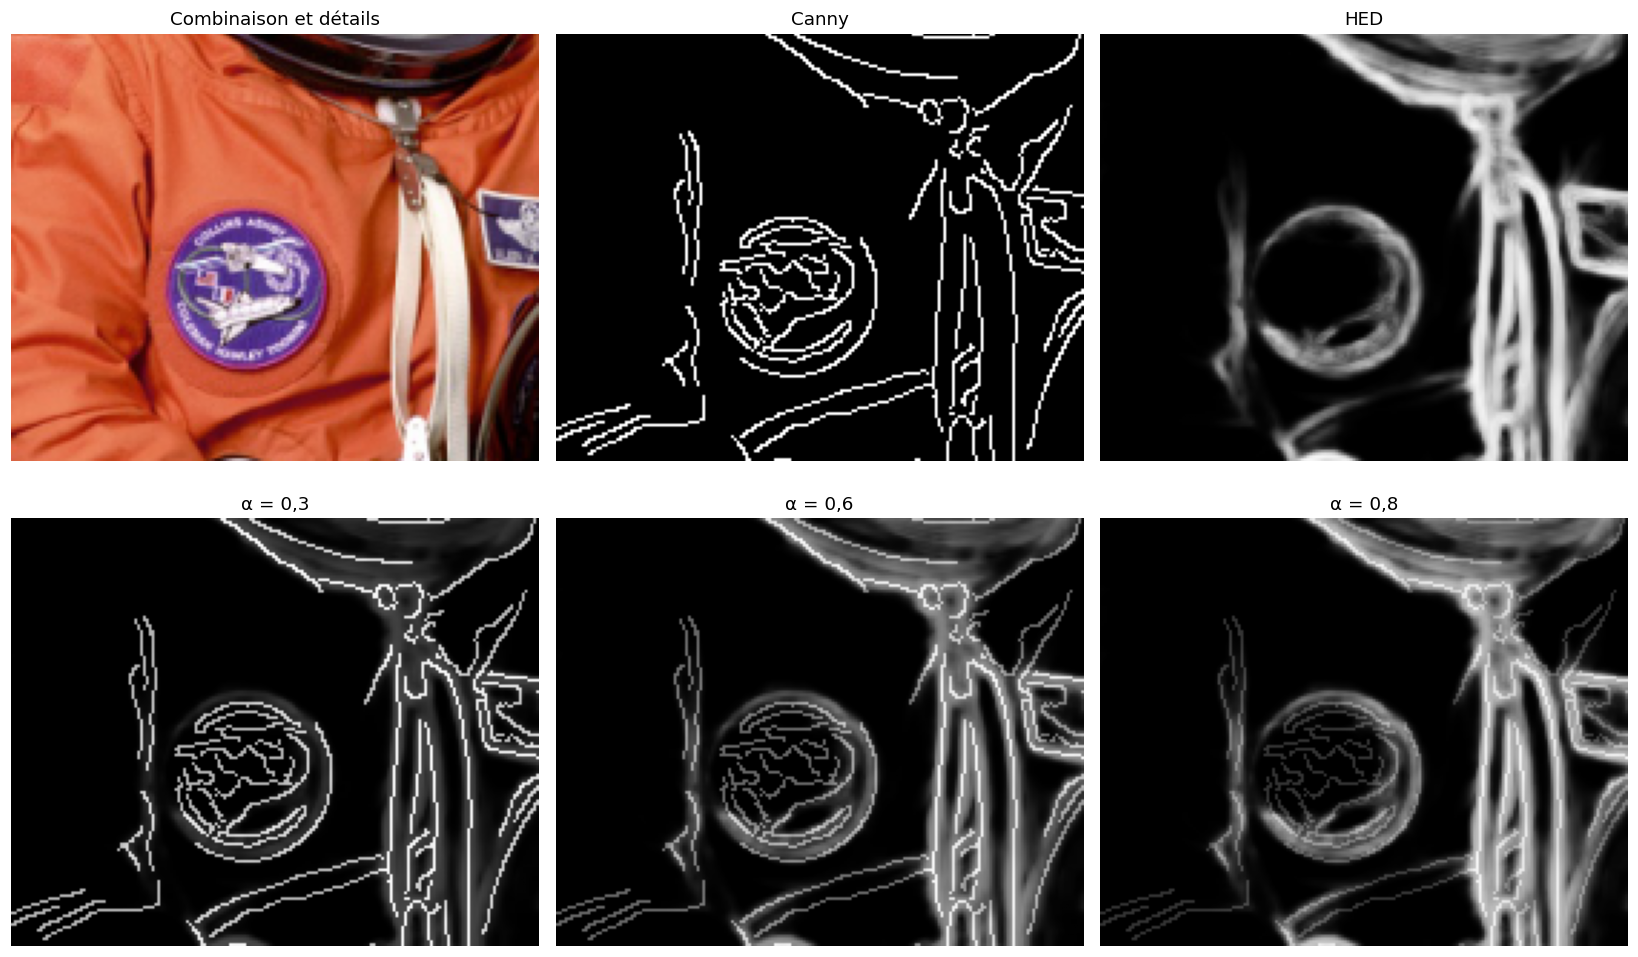

In [7]:
alphas = [0.3, 0.6, 0.8]
fusions = {a: a * hed + (1 - a) * canny_norm for a in alphas}
for a, f in fusions.items():
    assert f.shape == hed.shape == canny_norm.shape
    assert np.isfinite(f).all() and f.min() >= 0 and f.max() <= 1 + 1e-6
    save_map(f"fusion_{a:.1f}.png", f)
show_grid(list(fusions.values()), [f"Fusion α = {a:.1f}" for a in alphas], "C_fusions.png")

# Deux régions : tête/visage, puis combinaison/inscriptions.
regions = {"Tête et visage": (0.12, 0.46, 0.32, 0.60),
           "Combinaison et détails": (0.52, 0.91, 0.12, 0.60)}
for label, (y1, y2, x1, x2) in regions.items():
    ys, xs = slice(round(y1*h), round(y2*h)), slice(round(x1*w), round(x2*w))
    show_grid([rgb[ys, xs], canny_norm[ys, xs], hed[ys, xs],
               fusions[0.3][ys, xs], fusions[0.6][ys, xs], fusions[0.8][ys, xs]],
              [label, "Canny", "HED", "α = 0,3", "α = 0,6", "α = 0,8"],
              "C_zoom_visage.png" if "visage" in label else "C_zoom_combinaison.png")

### C.4. Choix du résultat le plus utile
Pour une **visualisation combinant grandes limites et détails**, on retient **α = 0,6**. Cette valeur maintient une contribution visible de Canny (40 %) tout en donnant davantage de poids aux structures de HED (60 %). Avec α = 0,3, les détails fins de Canny dominent davantage ; avec α = 0,8, les bandes de HED deviennent prépondérantes et les détails propres à Canny sont moins visibles.

Ce choix est qualitatif et dépend de l'objectif. Pour obtenir immédiatement un dessin binaire très fin, Canny seul peut être plus pratique. La fusion α = 0,6 n'est donc pas déclarée « meilleure » selon une métrique de précision : aucune vérité terrain n'est disponible.

## Partie D — Analyse et mini-compte rendu
### D.1. Protocole de mesure du coût
Chaque chaîne est exécutée une fois pour l'échauffement, puis **cinq fois**. On rapporte moyenne et écart-type en millisecondes. Les mesures excluent lecture des fichiers, chargement du modèle, affichage et sauvegarde.

Sobel et Canny incluent conversion en gris et flou. HED inclut création du blob, inférence, remise à taille et normalisation. La fusion complète recalcule Canny et HED ; une mesure supplémentaire isole seulement l'addition pondérée quand les cartes sont déjà disponibles. Toutes les méthodes utilisent la même image de travail et le même CPU.

In [8]:
def classical_input(bgr):
    return cv2.GaussianBlur(cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY), (5, 5), 1.2)

def run_canny():
    return cv2.Canny(classical_input(img), 100, 200).astype(np.float32) / 255.

def run_fusion():
    c = run_canny()
    _, hh = predict_hed(img)
    return 0.6 * hh + 0.4 * c

def benchmark(fn, repeats=5):
    fn()
    durations = []
    for _ in range(repeats):
        start = perf_counter()
        fn()
        durations.append(1000 * (perf_counter() - start))
    return float(np.mean(durations)), float(np.std(durations, ddof=1))

operations = {
    "Sobel": lambda: sobel_map(classical_input(img)),
    "Canny (100, 200)": run_canny,
    "HED": lambda: predict_hed(img),
    "Fusion α=0,6 (chaîne complète)": run_fusion,
    "Fusion seule (cartes disponibles)": lambda: 0.6 * hed + 0.4 * canny_norm,
}
timings = {name: benchmark(fn) for name, fn in operations.items()}
rows = ["| Méthode | Moyenne (ms) | Écart-type (ms) |", "|:--|--:|--:|"]
rows += [f"| {name} | {mean:.3f} | {std:.3f} |" for name, (mean, std) in timings.items()]
display(Markdown("\n".join(rows)))
with (OUT / "temps_execution.csv").open("w", newline="", encoding="utf-8") as f:
    writer = csv.writer(f)
    writer.writerow(["methode", "moyenne_ms", "ecart_type_ms"])
    writer.writerows((name, *values) for name, values in timings.items())
display(Markdown(f"Dans cette exécution, HED prend environ **{timings['HED'][0]/timings['Canny (100, 200)'][0]:.0f} fois** le temps de Canny. Cinq répétitions donnent une indication locale ; la charge de la machine et la taille de l'image influencent ces valeurs."))

| Méthode | Moyenne (ms) | Écart-type (ms) |
|:--|--:|--:|
| Sobel | 2.919 | 0.165 |
| Canny (100, 200) | 3.663 | 0.385 |
| HED | 1822.605 | 939.928 |
| Fusion α=0,6 (chaîne complète) | 1791.275 | 480.692 |
| Fusion seule (cartes disponibles) | 0.665 | 0.376 |

Dans cette exécution, HED prend environ **498 fois** le temps de Canny. Cinq répétitions donnent une indication locale ; la charge de la machine et la taille de l'image influencent ces valeurs.

### D.2. Tableau comparatif synthétique
La continuité et la sensibilité aux détails sont appréciées visuellement. La sensibilité au bruit ci-dessous est une propriété attendue des méthodes : l'image n'a pas fait l'objet d'une expérience de bruit contrôlée.

In [9]:
comparison = [
    ("Sobel", "Bandes larges ; pas de chaînage explicite", "Fortes réponses aux variations locales ; bruit atténué par le flou", "Sobel", "Visualise la force du gradient, sans binarisation"),
    ("Canny (100, 200)", "Lignes fines ; ruptures possibles aux faibles contrastes", "Détails contrastés conservés ; seuils et flou réduisent les réponses faibles", "Canny (100, 200)", "Rapide ; compromis précision spatiale / perte de détails"),
    ("HED", "Grandes structures plus larges et progressives", "Atténuation de certains détails ; dépend du domaine appris", "HED", "Carte continue ; contours parfois épais ; pas d'immunité au bruit"),
    ("Fusion α=0,6", "Superposition de lignes fines et bandes HED", "Peut réintroduire les détails et défauts des deux cartes", "Fusion α=0,6 (chaîne complète)", "Compromis visuel ; coût dominé par HED"),
]
header = "| Méthode | Continuité des contours | Sensibilité aux textures/bruit | Coût moyen CPU | Observations |\n|:--|:--|:--|--:|:--|"
body = [f"| {name} | {continuity} | {noise} | {timings[key][0]:.3f} ms | {obs} |" for name, continuity, noise, key, obs in comparison]
display(Markdown(header + "\n" + "\n".join(body)))
(OUT / "tableau_comparatif.md").write_text(header + "\n" + "\n".join(body), encoding="utf-8")

| Méthode | Continuité des contours | Sensibilité aux textures/bruit | Coût moyen CPU | Observations |
|:--|:--|:--|--:|:--|
| Sobel | Bandes larges ; pas de chaînage explicite | Fortes réponses aux variations locales ; bruit atténué par le flou | 2.919 ms | Visualise la force du gradient, sans binarisation |
| Canny (100, 200) | Lignes fines ; ruptures possibles aux faibles contrastes | Détails contrastés conservés ; seuils et flou réduisent les réponses faibles | 3.663 ms | Rapide ; compromis précision spatiale / perte de détails |
| HED | Grandes structures plus larges et progressives | Atténuation de certains détails ; dépend du domaine appris | 1822.605 ms | Carte continue ; contours parfois épais ; pas d'immunité au bruit |
| Fusion α=0,6 | Superposition de lignes fines et bandes HED | Peut réintroduire les détails et défauts des deux cartes | 1791.275 ms | Compromis visuel ; coût dominé par HED |

916

### D.3. Mesures descriptives des cartes
On mesure la proportion de pixels dépassant 0,5 et le nombre de composantes connexes (8-connexité). Le seuil est identique pour les cartes continues, mais celles-ci ne sont pas calibrées de manière identique : **ce tableau n'est pas un classement de qualité**. Les bandes épaisses peuvent fusionner des composantes et augmenter la densité sans améliorer les contours. Sobel est inclus uniquement à titre descriptif.

In [10]:
maps = {"Sobel": sobel, "Canny (50, 150)": canny_low / 255.,
        "Canny (100, 200)": canny_norm, "HED": hed,
        **{f"Fusion α={a:.1f}": f for a, f in fusions.items()}}
measures = []
for name, a in maps.items():
    mask = (a >= 0.5).astype(np.uint8)
    nlabels, _ = cv2.connectedComponents(mask, connectivity=8)
    measures.append((name, int(mask.sum()), 100 * float(mask.mean()), nlabels - 1))
lines = ["| Carte (seuil 0,5) | Pixels actifs | Densité (%) | Composantes |", "|:--|--:|--:|--:|"]
lines += [f"| {name} | {n} | {density:.2f} | {components} |" for name, n, density, components in measures]
display(Markdown("\n".join(lines)))
with (OUT / "mesures_cartes.csv").open("w", newline="", encoding="utf-8") as f:
    writer = csv.writer(f)
    writer.writerow(["carte", "pixels_actifs", "densite_pourcent", "composantes_8_connexes"])
    writer.writerows(measures)

| Carte (seuil 0,5) | Pixels actifs | Densité (%) | Composantes |
|:--|--:|--:|--:|
| Sobel | 3002 | 2.04 | 96 |
| Canny (50, 150) | 11747 | 7.97 | 188 |
| Canny (100, 200) | 8999 | 6.10 | 146 |
| HED | 27688 | 18.78 | 33 |
| Fusion α=0.3 | 8999 | 6.10 | 146 |
| Fusion α=0.6 | 13441 | 9.12 | 134 |
| Fusion α=0.8 | 22737 | 15.42 | 85 |

## 6. Réponses aux questions d'analyse
### Question 1 — Pourquoi appliquer un flou gaussien avant Canny ? Que se passe-t-il si le flou est trop important ?
La dérivation amplifie les variations rapides, y compris celles dues au bruit. Le flou gaussien réduit ces variations avant le calcul des gradients : Canny produit ainsi moins de petits contours parasites. Ici, le noyau $5\times5$ et $\sigma=1{,}2$ constituent un lissage léger. Un flou excessif réduit aussi les vrais gradients, supprime des détails fins et peut faire disparaître les limites peu contrastées. Deux contours proches peuvent être confondus. Il faut donc adapter le lissage à la résolution et au niveau de bruit.

### Question 2 — Quel est l'effet d'une augmentation des seuils de Canny sur le nombre de contours détectés ?
À image et prétraitement fixes, relever les seuils réduit les pixels admissibles : moins de points dépassent le seuil haut et moins de contours faibles peuvent être reliés à ces points forts. Le nombre de pixels de contour diminue ou reste identique. Les grandes limites très contrastées subsistent, tandis que des détails s'effacent. Le nombre de *composantes* ne suit pas nécessairement cette tendance, car une courbe peut se fragmenter. La partie A donne la diminution réellement mesurée entre (50, 150) et (100, 200).

### Question 3 — HED produit-il uniquement des contours binaires ? Comment interpréter les niveaux de gris ?
Non. HED produit une carte continue de scores : les régions claires correspondent à des réponses élevées et les régions sombres à des réponses faibles. Les valeurs intermédiaires expriment une réponse graduelle et peuvent entourer une limite forte ; elles ne sont pas des classes supplémentaires. Après min-max, elles indiquent une force relative et non une probabilité calibrée. Une carte binaire exige un seuillage explicite ; un amincissement ou une suppression des non-maxima peut être nécessaire pour obtenir des lignes très fines. Cette étape n'est pas incluse dans la fusion pondérée de base.

### Question 4 — Dans quelles zones HED apporte-t-il une information que Canny ne détecte pas, ou inversement ?
Sur la photographie étudiée, les zones de la tête, du visage et de la combinaison illustrent la complémentarité des réponses (agrandissements de la partie C). HED donne une réponse plus étendue autour de la tête et du bas du visage ; du côté gauche de l’image, la limite de la joue apparaît en bande dans HED, alors que Canny la laisse largement interrompue. À l'inverse, Canny représente nettement les yeux, la bouche et les motifs internes de l’écusson circulaire, très atténués dans HED. Ces différences proviennent du contexte multi-échelle de HED et de la décision locale par gradient de Canny. Une réponse supplémentaire n'est pas automatiquement un vrai contour utile : son intérêt dépend de l'objet recherché.

### Question 5 — La fusion améliore-t-elle toujours le résultat ? Donner un exemple de contours indésirables.
Non. Une moyenne pondérée ne sait pas décider quelle méthode a raison. Elle peut cumuler les faux positifs, épaissir les limites ou superposer deux contours légèrement décalés. Si l'objectif est de délimiter la silhouette de l'astronaute, les inscriptions et les plis internes de la combinaison sont des contours indésirables que Canny peut réintroduire dans la fusion. Sur un fond de feuilles ou de briques, elle peut aussi conserver beaucoup de texture. Ces motifs restent de vraies variations d'intensité, mais peuvent être inutiles pour la tâche visée.

### Question 6 — Quel est l'effet de α ? Comparer 0,3 et 0,8 sur l'image.
Avec $\alpha=0{,}3$, la fusion contient 30 % de HED et 70 % de Canny : les lignes fines et les détails locaux de Canny restent très visibles. Avec $\alpha=0{,}8$, elle contient 80 % de HED et 20 % de Canny : les contours progressifs et plus larges de HED dominent, tandis que les détails exclusifs à Canny s'atténuent. Cela se voit dans les régions du visage et de la combinaison. Par exemple, pour $C=1$ et $H\simeq0$, la fusion vaut environ 0,7 puis 0,2. Pour $C=0$ et $H=1$, elle vaut 0,3 puis 0,8. Le choix 0,6 correspond ici à un compromis visuel ; il n'est pas un optimum démontré.

### Question 7 — Quelle méthode choisir pour une application embarquée avec peu de ressources ?
Je choisirais Canny si l'application demande des contours fins et binaires avec peu de mémoire et un temps de traitement faible. Il n'exige pas de poids de réseau et son coût mesuré ici est nettement inférieur à celui de HED. Sobel peut être préférable si l'on souhaite seulement une carte de gradient et un traitement encore plus simple, mais il faut ensuite sélectionner et éventuellement amincir les contours. HED et la fusion deviennent envisageables si la qualité des structures apprises justifie le coût et si le matériel dispose d'un accélérateur adapté. Le choix doit être vérifié à la résolution et à la cadence de l'application réelle.

### Question 8 — Comment évaluer quantitativement avec une vérité terrain ?
Pour une prédiction binaire et une référence alignée, on compte les vrais positifs (VP), faux positifs (FP) et faux négatifs (FN). On peut calculer :

$$\mathrm{Précision}=\frac{VP}{VP+FP},\qquad
\mathrm{Rappel}=\frac{VP}{VP+FN},\qquad
F_1=\frac{2VP}{2VP+FP+FN},\qquad
\mathrm{IoU}=\frac{VP}{VP+FP+FN}.$$

La précision pénalise les contours ajoutés à tort ; le rappel pénalise les contours manqués ; F1 équilibre les deux. L'IoU mesure le recouvrement entre ensembles de pixels de contour. Pour HED et les fusions, on fait varier le seuil et on trace une courbe précision-rappel, ou on choisit le seuil sur un ensemble de validation. L'exactitude globale est peu informative, car les pixels de fond sont majoritaires.

Une comparaison exacte pixel par pixel pénalise fortement un décalage d'un pixel. Une évaluation de frontières plus réaliste utilise une tolérance spatiale annoncée et un appariement un-à-un des pixels de contour, éventuellement après amincissement. Il faut appliquer le même protocole à toutes les méthodes et utiliser plusieurs images. En l'absence de référence ici, les densités et composantes mesurées ne remplacent pas ces métriques.

### Exemple de calcul des métriques avec une référence disponible
Cette fonction réalise une comparaison **exacte pixel par pixel**, sans tolérance spatiale. Elle peut être utilisée avec une véritable annotation binaire, après vérification de son alignement. Aucun score n'est calculé contre une référence artificielle pour la photographie de ce TP.

In [11]:
def contour_metrics(prediction, reference, threshold=0.5):
    """prediction : scores dans [0,1] ; reference : masque booléen aligné."""
    prediction = np.asarray(prediction)
    reference = np.asarray(reference)
    if prediction.ndim != 2 or prediction.shape != reference.shape:
        raise ValueError("Les deux cartes doivent être 2D et de même taille.")
    if reference.dtype != np.bool_:
        raise TypeError("Convertir explicitement la vérité terrain en masque booléen.")
    if not np.isfinite(prediction).all() or prediction.min() < 0 or prediction.max() > 1:
        raise ValueError("Les scores doivent être finis et dans [0,1].")
    pred, ref = prediction >= threshold, reference
    tp = int(np.count_nonzero(pred & ref))
    fp = int(np.count_nonzero(pred & ~ref))
    fn = int(np.count_nonzero(~pred & ref))
    def ratio(a, b):
        return a / b if b else float("nan")  # Indéfini si dénominateur nul.
    return {"VP": tp, "FP": fp, "FN": fn,
            "precision": ratio(tp, tp + fp), "rappel": ratio(tp, tp + fn),
            "F1": ratio(2 * tp, 2 * tp + fp + fn), "IoU": ratio(tp, tp + fp + fn)}

# Exemple à activer uniquement avec une annotation réelle :
# gt_image = cv2.imread("verite_terrain.png", cv2.IMREAD_GRAYSCALE)
# gt = gt_image > 0  # À adapter au codage réel de l'annotation.
# print(contour_metrics(hed, gt, threshold=0.5))
print("Aucune vérité terrain fournie : aucun score de précision, rappel ou F1 annoncé.")

Aucune vérité terrain fournie : aucun score de précision, rappel ou F1 annoncé.


## 8. Extension facultative — Fusion logique et coût
La comparaison des temps répétés est donnée en partie D. On teste également l'union logique après seuillage de HED à 0,5 :

$$U=(H\geq0{,}5)\lor(C>0).$$

Cette union conserve chaque pixel accepté par l'une des méthodes. Elle ne peut donc contenir moins de pixels que chacune de ses deux entrées. Elle peut améliorer la couverture, mais aussi cumuler les contours indésirables. Elle se distingue de la somme pondérée, qui produit des intensités continues. L'option d'une seconde photographie n'est pas réalisée dans cette étude.

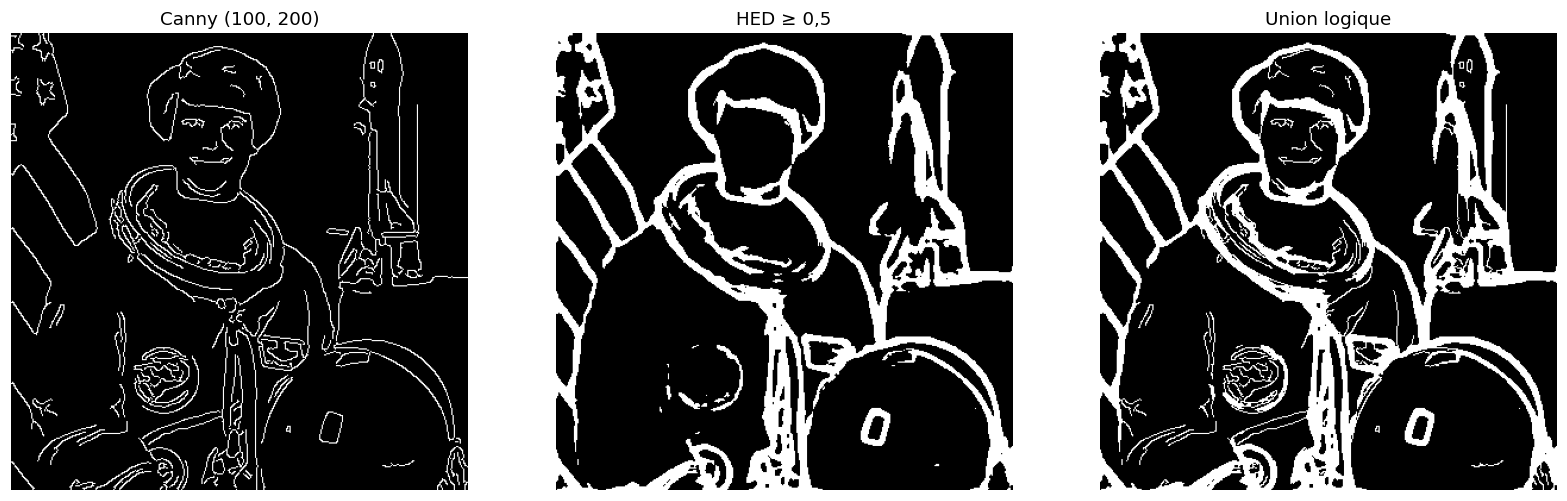

L'union contient **31,070 pixels**, contre **8,999** pour Canny et **27,688** pour HED seuillé. Elle ajoute **22,071 pixels** à Canny ; cet ajout ne démontre pas un gain de précision.

In [12]:
hed_binary = hed >= 0.5
union = np.logical_or(hed_binary, canny_norm > 0)
assert np.all(union[hed_binary]) and np.all(union[canny_norm > 0])
show_grid([canny_norm, hed_binary.astype(float), union.astype(float)],
          ["Canny (100, 200)", "HED ≥ 0,5", "Union logique"], "extension_union.png")
extra = np.count_nonzero(union & ~(canny_norm > 0))
display(Markdown(f"L'union contient **{np.count_nonzero(union):,} pixels**, contre **{np.count_nonzero(canny):,}** pour Canny et **{np.count_nonzero(hed_binary):,}** pour HED seuillé. Elle ajoute **{extra:,} pixels** à Canny ; cet ajout ne démontre pas un gain de précision."))
save_map("fusion_logique.png", union.astype(float))

## Conclusion générale
Sobel met en évidence la force des variations locales ; Canny extrait des lignes fines avec un coût faible ; HED produit une carte continue fondée sur des représentations multi-échelles, au prix d'un calcul plus important. La fusion pondérée permet de régler leur contribution. Sur l'exemple étudié, α = 0,6 est retenu pour visualiser conjointement les structures et les détails, tout en acceptant des contours plus épais et certaines réponses internes inutiles.

La fusion est donc un compromis réglable, pas une amélioration garantie. Une validation objective demanderait plusieurs images annotées, un protocole d'appariement de contours et des mesures de précision, rappel et F1. Les figures, paramètres et temps mesurés de ce notebook permettent de reproduire et de discuter l'expérience.
